<a href="https://colab.research.google.com/github/Vishagan-M/DL/blob/main/DL_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 20 Loss: 0.001959012688270637
Epoch 40 Loss: 0.003233075574306505
Epoch 60 Loss: 0.002049678861762264
Epoch 80 Loss: 0.0017718160192349128
Epoch 100 Loss: 0.002230522838155074
Epoch 20 Loss: 0.002303266548551619
Epoch 40 Loss: 0.0014980448260238127
Epoch 60 Loss: 0.0011239513239291097
Epoch 80 Loss: 0.0010838667471294425
Epoch 100 Loss: 0.0007111737670909081


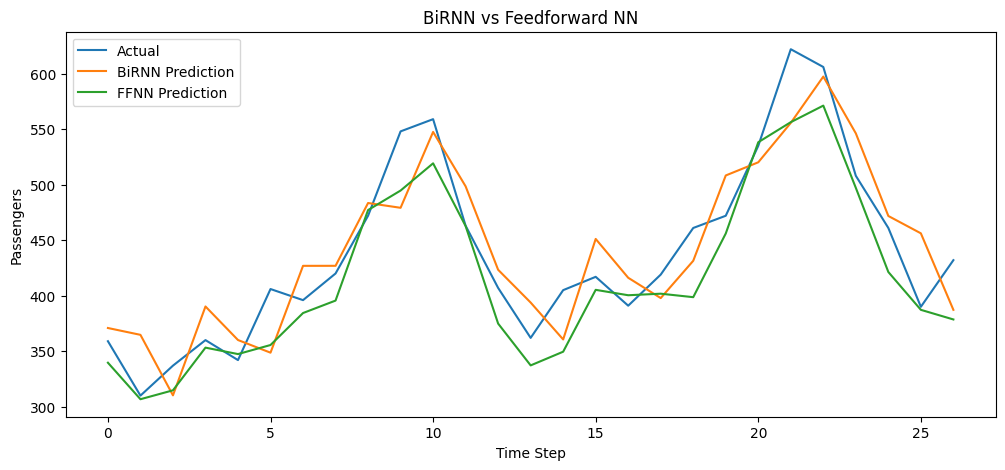

BiRNN MSE: 1332.9073486328125
FFNN MSE: 1042.38818359375


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from torch.utils.data import TensorDataset, DataLoader

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/monthly-airline-passengers.csv"

df = pd.read_csv(url, usecols=[1])

data = df.values.astype("float32")

scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data)

SEQ_LENGTH = 10

X = np.array([
    data_scaled[i:i + SEQ_LENGTH]
    for i in range(len(data_scaled) - SEQ_LENGTH)
])

y = np.array([
    data_scaled[i + SEQ_LENGTH]
    for i in range(len(data_scaled) - SEQ_LENGTH)
])

train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train)

X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=16,
    shuffle=True
)

class BiRNN(nn.Module):
    def __init__(self):
        super(BiRNN, self).__init__()

        self.rnn = nn.RNN(
            1, 64, 1,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class FeedforwardNN(nn.Module):
    def __init__(self):
        super(FeedforwardNN, self).__init__()

        self.fc1 = nn.Linear(SEQ_LENGTH, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.fc2(self.relu(self.fc1(x)))

def train_model(model, loader, epochs=100):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        loss_epoch = 0

        for seqs, targets in loader:
            optimizer.zero_grad()

            outputs = model(seqs)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            loss_epoch += loss.item()

        if (epoch + 1) % 20 == 0:
            print(
                "Epoch", epoch + 1,
                "Loss:", loss_epoch / len(loader)
            )

def evaluate_model(model, X):
    model.eval()

    with torch.no_grad():
        return model(X).numpy()

birnn = BiRNN()
train_model(birnn, train_loader)

ffnn = FeedforwardNN()
train_model(ffnn, train_loader)

pred_birnn = evaluate_model(birnn, X_test_tensor)
pred_ffnn = evaluate_model(ffnn, X_test_tensor)

pred_birnn_inv = scaler.inverse_transform(pred_birnn)
pred_ffnn_inv = scaler.inverse_transform(pred_ffnn)
y_test_inv = scaler.inverse_transform(y_test)

plt.figure(figsize=(12, 5))

plt.plot(y_test_inv, label="Actual")
plt.plot(pred_birnn_inv, label="BiRNN Prediction")
plt.plot(pred_ffnn_inv, label="FFNN Prediction")

plt.legend()
plt.title("BiRNN vs Feedforward NN")
plt.xlabel("Time Step")
plt.ylabel("Passengers")
plt.show()

mse_birnn = mean_squared_error(y_test_inv, pred_birnn_inv)
mse_ffnn = mean_squared_error(y_test_inv, pred_ffnn_inv)

print("BiRNN MSE:", mse_birnn)
print("FFNN MSE:", mse_ffnn)